## CNN avec tensorFlow

In [3]:
# Import Librairy
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import regularizers
import numpy as np
import matplotlib.pyplot as plt #can be replace by plotly
from pathlib import Path


### Hyperparametres
Epoch:
Train, test, valid split:

On décide de partir sur cette répartition car

In [4]:
train_split=0.75
test_split=0.15
val_split=0.1

### Import un dataset

Divisé en deux dataset plus petit : \n
- Train
- Test

Train sera utilisé pour entrainé le modele à reconnaitre les images (reconnaissance binaire ou d'un groupe d'objet), test sera la pour "valider" cet entrainement et voir si le modèle doit etre retoucher pour obtenir un meilleur résultat.
Partager le dataset par rapport au nombre d'image dans le dataset

In [5]:
def load_and_count_images(data_dir):
    """
    Compte les images dans chaque sous-dossier (True/False).
    """
    data_path = Path(data_dir)
    counts = {}
    for class_dir in sorted(data_path.iterdir()):
        if class_dir.is_dir():
            n = len([f for f in class_dir.iterdir() 
                     if f.is_file() and f.suffix.lower() in ['.jpg', '.jpeg', '.png']])
            counts[class_dir.name] = n
    return counts

resolution = "512x512" # À adapter selon le dossier choisi
dossier_racine = Path(f"../data/process/{resolution}")
img_size = (int(resolution.split('x')[0]), int(resolution.split('x')[1]))#transform l'image pour qu'elle soit lisible par tensorflow


"""
Split en trois dataset avec 75/15/10
"""
# Charger le dataset complet non-batché pour un split précis
full_dataset = tf.keras.utils.image_dataset_from_directory(
    dossier_racine,
    labels='inferred',
    label_mode='int',
    class_names=['False', 'True'],
    image_size=img_size,
    batch_size=None, # Important : on gère les batchs après le split
    shuffle=True,
    seed=42
)

# Calcul des tailles en entiers
dataset_size = len(full_dataset)
train_size = int(0.75 * dataset_size)
test_size = int(0.15 * dataset_size)
val_size = int(0.10 * dataset_size)

# Split du dataset
train_dataset = full_dataset.take(train_size)
test_val_dataset = full_dataset.skip(train_size)
test_dataset = test_val_dataset.take(test_size)
val_dataset = test_val_dataset.skip(test_size)

def extract_numpy_arrays(dataset):
    images = []
    labels = []
    for img, label in dataset:
        images.append(img.numpy())
        labels.append(label.numpy())
    return np.array(images), np.array(labels)

"""
Load Dataset
"""
x_train, y_train = extract_numpy_arrays(train_dataset)
x_test, y_test = extract_numpy_arrays(test_dataset)
x_val, y_val = extract_numpy_arrays(val_dataset)

"""
Data augmentation pour que chaque dataset a les valeurs équivalentes pour l'entrainement
"""
def new_img(X,y):
    """
    Create new images with flip for data augmentation
    """

    fake_img=np.where(y == 0)[0]
    true_img=np.where(y == 1)[0]
    
    diff = len(true_img) - len(fake_img)

    if diff == 0:
        return X, y
    if diff > 0:
        clone = np.random.choice(fake_img, size=diff, replace=True)
        
        x_supp = X[clone]
        y_supp = y[clone]

        x_supp = np.array([np.fliplr(img) for img in x_supp])

        X = np.concatenate([X, x_supp], axis=0)
        y = np.concatenate([y, y_supp], axis=0)
    else:
        clone = np.random.choice(true_img, size=abs(diff), replace=True)
                
        x_supp = X[clone]
        y_supp = y[clone]
        
        x_supp = np.array([np.fliplr(img) for img in x_supp])
        
        X = np.concatenate([X, x_supp], axis=0)
        y = np.concatenate([y, y_supp], axis=0)
        
    perm = np.random.permutation(len(X))
    X = X[perm]
    y = y[perm]

    return X,y

x_train,y_train=new_img(x_train,y_train)

print("Train size:", len(x_train))
print("Test size:", len(x_test))
print("Valid size:", len(x_val))

print("Répartition Train :")
print(" - False (0) :", np.sum(y_train == 0))
print(" - True (1)  :", np.sum(y_train == 1))

Found 41399 files belonging to 2 classes.


MemoryError: Unable to allocate 91.0 GiB for an array with shape (31049, 512, 512, 3) and data type float32

### Shape
Les valeurs habituelle d'une image son entre 0 et 255, pour cela il faut normaliser cela en premier lieu divisant par 255 pour avoir des valeurs comprise entre 0 et 1. Car cela va aidé à la descente de gradient et rentre plus rapide l'entrainement du modele. Uniquement Pour X car y est généralement les labels de l'image si classification binaire, 1 pour l'image est une photo 0 pas une photo.

In [ ]:
x_train, x_test,x_val = x_train / 255.0, x_test / 255.0, x_val / 255.0
x_train.shape, x_test.shape,x_val.shape

((46986, 64, 64, 3), (6209, 64, 64, 3), (4141, 64, 64, 3))

In [ ]:
print("Dimensions de test :", x_test.shape, y_test.shape)

Dimensions de test : (6209, 64, 64, 3) (6209,)


### EarlyCallback et backpropagation

- On utilise le EarlyCallback pour stopper l'entrainement du modèle quand la valeur cible ne s'améliore pas, on défini une patience qui s'y active après la valeur x défini est atteinte et que pendant cette période il y a eu aucune amélioration et limité l'overfitting. Restore_best_weights va restoré l'epoch avec la meilleure valeur obtenue quand le modèle va se stopper.

In [ ]:
early_stopping_callback = EarlyStopping(
    monitor='val_loss', # The metric to monitor for improvement
    patience=8,         # Number of epochs with no improvement after which training will be stopped
    verbose=1,          # Show a message when stopping
    restore_best_weights=True # Restores model weights from the epoch with the best value of the monitored quantity.
)

## Création Modele

En utilisant plusieurs couches dans le modèle pour le CNN, cela permet de trier et determiné l'ouput que l'on souhaite, dans les couches. On trouve :
- ***input_shape :*** est la taille d'entrée et le nombre channel de l'image et se défini comme (hauteur, largeur, channel). Vous pouvez rajouter aussi batch_size.
- ***Convolutional Layer:*** Chargé d'extraire des caractéristiques locales de l'image avec un kernel d'une taille défini par souvent de matrice 3x3 en passant sur toute l'image, cela permet d'extraire les informations de l'image, fonctionne avec Pooling.
- ***Pooling Layer:*** Le pooling layer fonctionne avec le Convolutional layer, il y a deux type de pooling soit average Pooling ou Max Pooling, ce layer permet de réduire le taille des caractèristiques obtenu par la couche Convolutional pour améliorer la vitesse d'entrainement, le plus souvent on utilise MaxPooling, souvent une fenetre entre 2x2 et 3x3 en prennant le maximun de la fenetre et mets en évidence les caractéristique détecté dans le layer précédent.
- ***Dense :*** Un Dense layer est un layer avec les neuronnes tous interconnecté, il est placé à la fin après flatten car il ne peut comprendre uniquement des vecteurs en une dimension. Pour la couche de sortie est dense, tu défini avec softmax ou sigmoid par rapport à ton besoin. Sigmoid = 1 dense layer de sortie car on l'utilise pour la classification binaire, Softmax = depend du nbr de classe à prédire pour la classification multi-classe.
- ***Flatten :*** Transforme les layers de plusieurs dimensions en un vecteur de 1 seule dimension pour que les Denses layers puissent traduire l'image.
- ***Dropout:*** Désactive certains neurones pour éviter l'overfitting, il faut souvent tester plusieurs valeurs comprise entre 0 et 1 pour obtenir le meilleur parametres mais le plus souvent on trouve une valeur entre 0.1 et 0.4.
- ***L2 regularization :*** Va appliqué une pénalité sur les poids trop grand, cela force pendant l'optimisation des poids se rapproche de 0, tu décides avec l'hyperparamètres lambda ($\lambda$) la puissance de cette pénalité.


In [ ]:
model = keras.Sequential([
    keras.Input(shape=(512, 512, 3)),
    
    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Dropout(0.1),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Dropout(0.1),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Dropout(0.1),
    
    layers.Flatten(),
    layers.Dense(128, activation='relu',kernel_regularizer=regularizers.l2(0.001)),
    layers.Dense(10, activation='sigmoid',kernel_regularizer=regularizers.l2(0.001))
])

model.summary()


NameError: name 'keras' is not defined

### Compilé et L'optimisateur

On utilise un optimiser pour mettre à jour les poids en utilisant la descente de gradient lors de la backpropagation, le plus souvent on utilise l'agorithme Adam qui mets à jour automatiquement le Learning rate pour chaque poids en améliorant la vitesse et les performances d'entrainement.
Lorsqu'on compile le modèle avec TensorFlow, on choisit la métrique que l'on peut observé, ici l'accuracy de notre modèle. 
La loss fonction est utilisé pour calculé la différence entre les prédictions de notre modèle et les véritables images. Plusieurs méthodes sont disponible pour le CNN:
- Binary Cross-Entropy (Pour la classification binaire)
- Categorical Cross-Entropy (Pour la classification de plusieurs classes)
- Sparse Categorical Crossentropy (Pour la classification de plusieurs classes, mais les labels sont des numéros entier 1,2 etc...)

In [ ]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

### Lancement du modèle
***Les epochs:*** sont le nombre de fois que le modèle s'entraine

***Validation Split:*** est le % du dataset utilisé pour valider l'entrainement.

***Model.fit:*** est le lancement de l'entrainement du modèle.

***Model.evaluate:*** Permet d'evaluer le model sur sa precision et si les résultats sont proche des vrai images avec le dataset de Teest.

In [ ]:
all_callbacks = [early_stopping_callback]
history =model.fit(x_train, y_train, epochs=10,callbacks=all_callbacks, validation_split=0.1)

# Evaluate the model on the unseen test data
test_loss, test_accuracy = model.evaluate(x_test, y_test)
print(f"\nTest Accuracy: {test_accuracy}")

Epoch 1/10
1322/1322 ━━━━━━━━━━━━━━━━━━━━ 18s 14ms/step - accuracy: 0.9242 - loss: 0.2461 - val_accuracy: 0.9285 - val_loss: 0.2319
Epoch 2/10
1322/1322 ━━━━━━━━━━━━━━━━━━━━ 17s 13ms/step - accuracy: 0.9301 - loss: 0.2357 - val_accuracy: 0.9313 - val_loss: 0.2326
Epoch 3/10
1322/1322 ━━━━━━━━━━━━━━━━━━━━ 19s 14ms/step - accuracy: 0.9347 - loss: 0.2289 - val_accuracy: 0.9187 - val_loss: 0.2636
Epoch 4/10
1322/1322 ━━━━━━━━━━━━━━━━━━━━ 17s 13ms/step - accuracy: 0.9394 - loss: 0.2187 - val_accuracy: 0.9202 - val_loss: 0.2843
Epoch 5/10
1322/1322 ━━━━━━━━━━━━━━━━━━━━ 18s 14ms/step - accuracy: 0.9429 - loss: 0.2102 - val_accuracy: 0.9251 - val_loss: 0.2718
Epoch 6/10
1322/1322 ━━━━━━━━━━━━━━━━━━━━ 18s 14ms/step - accuracy: 0.9468 - loss: 0.2049 - val_accuracy: 0.9081 - val_loss: 0.3125
Epoch 7/10
1322/1322 ━━━━━━━━━━━━━━━━━━━━ 18s 13ms/step - accuracy: 0.9495 - loss: 0.2006 - val_accuracy: 0.9310 - val_loss: 0.2544
Epoch 8/10
1322/1322 ━━━━━━━━━━━━━━━━━━━━ 18s 14ms/step - accuracy: 0.9511 -

### Graphique des résultats

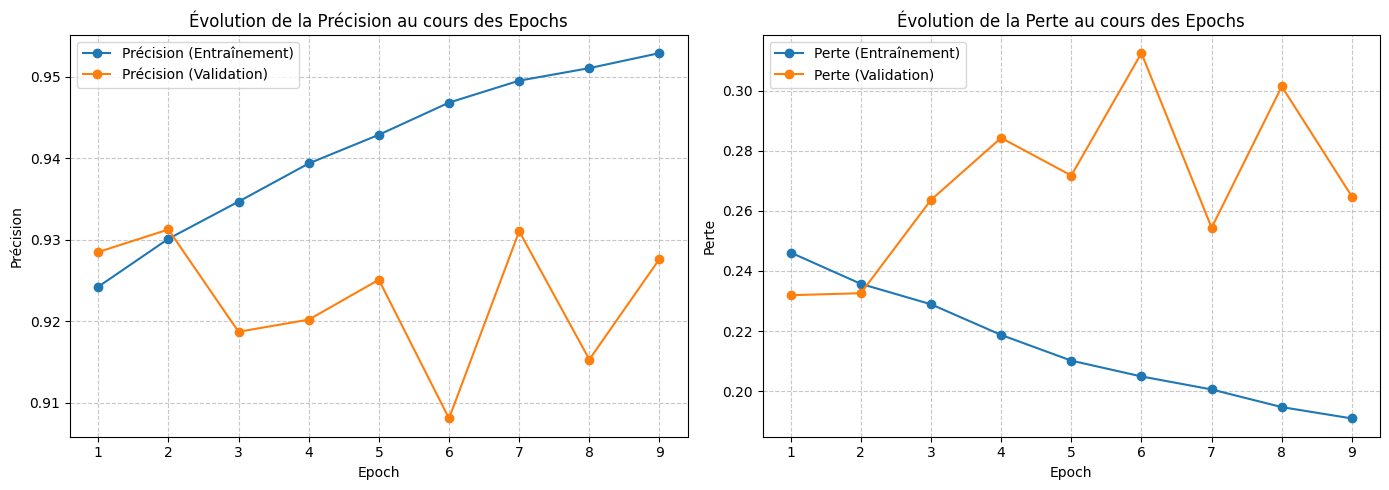

In [ ]:
hist_dict = history.history

epochs = range(1, len(hist_dict['accuracy']) + 1)

plt.figure(figsize=(14, 5))

# 1. Graphique de la Précision (Accuracy)
plt.subplot(1, 2, 1) # (1 ligne, 2 colonnes, position 1)
plt.plot(epochs, hist_dict['accuracy'], label='Précision (Entraînement)', marker='o')
plt.plot(epochs, hist_dict['val_accuracy'], label='Précision (Validation)', marker='o')
plt.title('Évolution de la Précision au cours des Epochs')
plt.xlabel('Epoch')
plt.ylabel('Précision')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

# 2. Graphique de la Perte (Loss)
plt.subplot(1, 2, 2) # (1 ligne, 2 colonnes, position 2)
plt.plot(epochs, hist_dict['loss'], label='Perte (Entraînement)', marker='o')
plt.plot(epochs, hist_dict['val_loss'], label='Perte (Validation)', marker='o')
plt.title('Évolution de la Perte au cours des Epochs')
plt.xlabel('Epoch')
plt.ylabel('Perte')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

### Export du modèle

In [ ]:
model.save("Modele_cnn.keras")